# Cyclistic: how do annual members and casual riders use bikes differently?
Google Data Analytics Capstone, Track A. Phases: **Ask → Prepare → Process → Analyze → Share → Act**.
Heavy lifting runs in **DuckDB (SQL)** directly on the CSV files, so 12 months (~5–6 million trips) fit on an 8 GB laptop; small aggregated results go to **pandas** for charts.

## 1. Ask
- **Business task:** identify how annual members and casual riders use Cyclistic bikes differently, so the marketing team can design a strategy to convert casual riders into annual members.
- **Stakeholders:** Lily Moreno (director of marketing), Cyclistic marketing analytics team, Cyclistic executive team.
- **Metrics:** share of rides, median ride length, weekday vs weekend share, hourly profile, monthly seasonality, bike type mix, top stations, round-trip share.

## 2. Prepare
Data: Divvy trip data 2025-11 → 2026-10 (`python scripts/download_data.py`). License: https://divvybikes.com/data-license-agreement. Details in `docs/data_sources.md`.

In [1]:
from pathlib import Path
import duckdb, pandas as pd, matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN, FIG = ROOT / "data/raw", ROOT / "data/clean", ROOT / "figures"
CLEAN.mkdir(parents=True, exist_ok=True); FIG.mkdir(exist_ok=True)
con = duckdb.connect(str(CLEAN / "cyclistic.duckdb"))
con.execute("SET memory_limit = '3GB'")
sorted(p.name for p in RAW.glob("*-divvy-tripdata.csv"))

['202511-divvy-tripdata.csv',
 '202512-divvy-tripdata.csv',
 '202601-divvy-tripdata.csv',
 '202602-divvy-tripdata.csv',
 '202603-divvy-tripdata.csv',
 '202604-divvy-tripdata.csv',
 '202605-divvy-tripdata.csv',
 '202606-divvy-tripdata.csv',
 '202607-divvy-tripdata.csv',
 '202608-divvy-tripdata.csv',
 '202609-divvy-tripdata.csv',
 '202610-divvy-tripdata.csv']

In [2]:
# Load all 12 monthly files into one table; keep the source file name for checks
con.execute(f'''
CREATE OR REPLACE TABLE trips_raw AS
SELECT * FROM read_csv('{RAW}/*-divvy-tripdata.csv', union_by_name = true, filename = true,
                       types = {{'started_at': 'TIMESTAMP', 'ended_at': 'TIMESTAMP'}})
''')
con.sql("DESCRIBE trips_raw").df()

,column_name,column_type,null,key,default,extra
0,ride_id,VARCHAR,YES,None,None,None
1,rideable_type,VARCHAR,YES,None,None,None
2,started_at,TIMESTAMP,YES,None,None,None
3,ended_at,TIMESTAMP,YES,None,None,None
4,start_station_name,VARCHAR,YES,None,None,None
5,start_station_id,VARCHAR,YES,None,None,None
6,end_station_name,VARCHAR,YES,None,None,None
7,end_station_id,VARCHAR,YES,None,None,None
8,start_lat,DOUBLE,YES,None,None,None
9,start_lng,DOUBLE,YES,None,None,None


In [3]:
# Rows per file and a first look at data quality
con.sql('''
SELECT regexp_extract(filename, '(\\d{6})') AS month_file, count(*) AS rides,
       count(*) FILTER (WHERE start_station_name IS NULL) AS no_start_station,
       count(*) FILTER (WHERE end_lat IS NULL)            AS no_end_coords
FROM trips_raw GROUP BY 1 ORDER BY 1
''').df()

,month_file,rides,no_start_station,no_end_coords
0,202511,356628,76280,357
1,202512,140534,26926,122
2,202601,137787,24553,196
3,202602,201450,32069,129
4,202603,317037,57774,283
5,202604,448252,91989,362
6,202605,653704,137282,590
7,202606,762550,158750,698
8,202607,869051,189216,801
9,202608,868191,189327,683


In [4]:
con.sql("SELECT rideable_type, member_casual, count(*) n FROM trips_raw GROUP BY ALL ORDER BY ALL").df()

,rideable_type,member_casual,n
0,classic_bike,casual,536098
1,classic_bike,member,1223157
2,electric_bike,casual,1703315
3,electric_bike,member,2831881


## 3. Process
Every step is logged with row counts → copy the table into `docs/changelog.md`.

In [5]:
steps = []
def log(name, sql_count):
    n = con.execute(sql_count).fetchone()[0]; steps.append((name, n)); print(f"{name:<55} {n:>10,}")

log("raw rows", "SELECT count(*) FROM trips_raw")
log("distinct ride_id", "SELECT count(DISTINCT ride_id) FROM trips_raw")

con.execute('''
CREATE OR REPLACE TABLE trips AS
WITH dedup AS (
  SELECT *, row_number() OVER (PARTITION BY ride_id ORDER BY started_at) AS rn FROM trips_raw
)
SELECT ride_id, rideable_type, member_casual, started_at, ended_at,
       start_station_name, end_station_name, start_lat, start_lng, end_lat, end_lng,
       date_diff('second', started_at, ended_at) / 60.0 AS ride_length_min,
       dayname(started_at)                      AS day_of_week,
       isodow(started_at)                       AS dow,          -- 1 = Monday … 7 = Sunday
       hour(started_at)                         AS hour,
       strftime(started_at, '%Y-%m')            AS month,
       (start_station_name = end_station_name)  AS round_trip
FROM dedup
WHERE rn = 1
  AND member_casual IN ('member', 'casual')
  AND date_diff('second', started_at, ended_at) BETWEEN 60 AND 86400     -- 1 min .. 24 h
  AND coalesce(upper(start_station_name), '') NOT LIKE '%TEST%'
  AND coalesce(upper(end_station_name),   '') NOT LIKE '%TEST%'
  AND coalesce(upper(start_station_name), '') NOT LIKE '%REPAIR%'
  AND started_at >= TIMESTAMP '2025-11-01' AND started_at < TIMESTAMP '2026-11-01'   -- analysis window
''')
log("clean rows (dedup, 1 min–24 h, no test/repair, 2025-11-01..2026-10-31)", "SELECT count(*) FROM trips")
con.execute(f"COPY trips TO '{CLEAN}/trips_clean.parquet' (FORMAT parquet)")
pd.DataFrame(steps, columns=["step", "rows"])

raw rows                                                 6,294,451


distinct ride_id                                         6,294,416


clean rows (dedup, 1 min–24 h, no test/repair, 2025-11-01..2026-10-31)  6,130,112


,step,rows
0,raw rows,6294451
1,distinct ride_id,6294416
2,"clean rows (dedup, 1 min–24 h, no test/repair,...",6130112


## 4. Analyze
All shares are within each rider type unless stated otherwise. Medians are used for ride length because the distribution is strongly right-skewed.

In [6]:
COLORS = {"member": "#3f3d9c", "casual": "#d6336c"}
q = lambda sql: con.sql(sql).df()

overview = q('''
SELECT member_casual,
       count(*) AS rides,
       round(100.0 * count(*) / sum(count(*)) OVER (), 1)                  AS pct_rides,
       round(median(ride_length_min), 1)                                   AS median_min,
       round(quantile_cont(ride_length_min, 0.9), 1)                       AS p90_min,
       round(100 * avg((ride_length_min > 30)::INT), 1)                    AS pct_over_30min,
       round(100 * avg((dow >= 6)::INT), 1)                                AS pct_weekend,
       round(100 * avg((dow <= 5 AND (hour BETWEEN 7 AND 9 OR hour BETWEEN 16 AND 18))::INT), 1) AS pct_commute_window,
       round(100 * avg(round_trip::INT), 1)                                AS pct_round_trip_known_stations,
       round(100 * avg((rideable_type = 'electric_bike')::INT), 1)         AS pct_ebike,
       round(100 * avg((month BETWEEN '2026-05' AND '2026-09')::INT), 1)   AS pct_may_sep
FROM trips GROUP BY 1 ORDER BY 1''')
overview

,member_casual,rides,pct_rides,median_min,p90_min,pct_over_30min,pct_weekend,pct_commute_window,pct_round_trip_known_stations,pct_ebike,pct_may_sep
0,casual,2162170,35.3,11.1,35.4,13.2,37.6,25.1,7.4,75.4,69.3
1,member,3967942,64.7,8.7,23.4,5.4,23.7,38.5,2.2,69.2,58.5


In [7]:
by_day = q("SELECT member_casual, dow, day_of_week, count(*) rides, median(ride_length_min) median_min FROM trips GROUP BY ALL ORDER BY dow")
by_day["share"] = 100 * by_day.rides / by_day.groupby("member_casual").rides.transform("sum")

by_hour = q("SELECT member_casual, (dow >= 6) AS weekend, hour, count(*) rides FROM trips GROUP BY ALL ORDER BY hour")
by_hour["share"] = 100 * by_hour.rides / by_hour.groupby(["member_casual", "weekend"]).rides.transform("sum")

by_month = q("SELECT member_casual, month, count(*) rides, median(ride_length_min) median_min FROM trips GROUP BY ALL ORDER BY month")
seasonality = by_month.groupby("member_casual").rides.agg(peak="max", trough="min")
seasonality["peak_to_trough"] = (seasonality.peak / seasonality.trough).round(1)

casual_share_by_month = by_month.pivot(index="month", columns="member_casual", values="rides")
casual_share_by_month["casual_share"] = (100 * casual_share_by_month.casual / casual_share_by_month.sum(axis=1)).round(1)

by_type = q("SELECT member_casual, rideable_type, count(*) rides FROM trips GROUP BY ALL")
stations = q('''
SELECT start_station_name, count(*) FILTER (WHERE member_casual = 'casual') AS casual_rides, count(*) AS all_rides,
       round(100.0 * count(*) FILTER (WHERE member_casual = 'casual') / count(*), 1) AS casual_share,
       avg(start_lat) AS lat, avg(start_lng) AS lng
FROM trips WHERE start_station_name IS NOT NULL GROUP BY 1 ORDER BY casual_rides DESC LIMIT 20''')
display(seasonality, casual_share_by_month[["casual_share"]].T, stations.head(10))

,peak,trough,peak_to_trough
member_casual,,,
casual,345591,23880,14.5
member,511048,109381,4.7


month,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
member_casual,,,,,,,,,,,,
casual_share,27.3,19.9,17.9,20.3,27.5,29.2,37.1,40.1,40.8,39.6,37.8,35.4


,start_station_name,casual_rides,all_rides,casual_share,lat,lng
0,Navy Pier,49979,65934,75.8,41.892278,-87.612043
1,DuSable Lake Shore Dr & Monroe St,28238,36038,78.4,41.880959,-87.616743
2,Michigan Ave & Oak St,20705,34259,60.4,41.900961,-87.623776
3,Millennium Park,17012,25510,66.7,41.881033,-87.624084
4,DuSable Lake Shore Dr & North Blvd,16751,30826,54.3,41.911722,-87.626804
5,Shedd Aquarium,16196,19802,81.8,41.867227,-87.615359
6,Theater on the Lake,14982,26241,57.1,41.926277,-87.630835
7,Dusable Harbor,13770,19200,71.7,41.886977,-87.612814
8,Field Museum,10370,12796,81.0,41.865312,-87.617870
9,Montrose Harbor,10156,18157,55.9,41.963981,-87.638181


In [8]:
# Weekday morning peak: share of weekday rides that start at 07:00–08:59
morning = by_hour[(~by_hour.weekend) & by_hour.hour.isin([7, 8])].groupby("member_casual").share.sum().round(1)
morning

member_casual
casual     7.7
member    15.2
Name: share, dtype: float64

### Key findings
1. **Casual riders take one in three rides, but their share is seasonal**: 35.3% of all rides over the year, from 17.9% in January to 40.8% in July 2026.
2. **Casual rides are longer**: median 11.1 vs 8.7 minutes (+28%); the 90th percentile is 35.4 vs 23.4 minutes.
3. **Casual riders ride on weekends**: 37.6% of casual rides fall on Saturday or Sunday (Saturday alone 21.5%) vs 23.7% for members.
4. **Members commute**: both groups peak at 17:00 on weekdays, but members also have a morning peak (07:00–08:59 holds ~15% of their weekday rides vs ~8% for casual riders) and 38.5% of member rides fall in weekday commute windows vs 25.1% for casual riders.
5. **Casual demand is concentrated in summer**: the busiest month has ~14.5× the casual rides of the quietest month (members ~4.7×); 69.3% of casual rides happen May–September vs 58.5% for members.
6. **The lakefront is casual territory**: casual riders make 76–82% of rides at Navy Pier, Shedd Aquarium, Field Museum and DuSable Lake Shore Dr & Monroe St; round trips are 7.4% of casual rides vs 2.2% for members (rides with known stations).
7. **A commuter-like casual segment exists**: 25.1% of casual rides (~540k) happen on weekdays at commute hours — riders who already behave like members.

## 5. Share
Every chart title states the finding. Member = indigo, casual = pink on every chart.

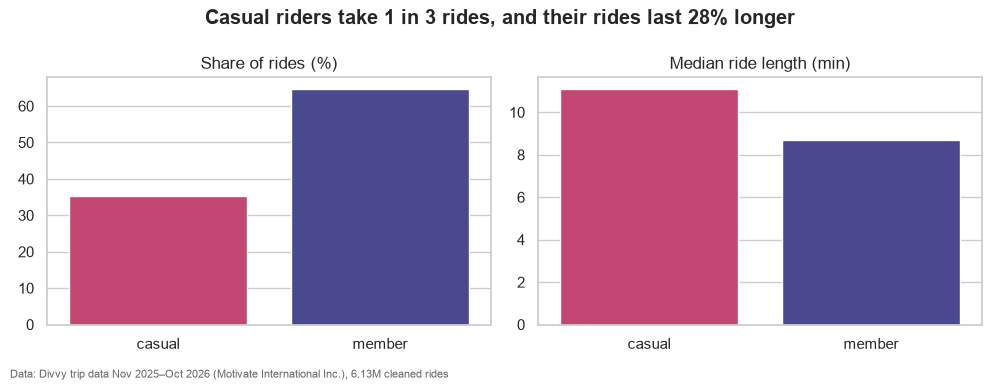

In [9]:
def finish(fig, name):
    fig.text(0.01, 0.01, "Data: Divvy trip data Nov 2025–Oct 2026 (Motivate International Inc.), 6.13M cleaned rides", fontsize=8, color="#666")
    fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(FIG / name, dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
sns.barplot(data=overview, x="member_casual", y="pct_rides", hue="member_casual", palette=COLORS, ax=axes[0], legend=False)
axes[0].set(title="Share of rides (%)", xlabel="", ylabel="")
sns.barplot(data=overview, x="member_casual", y="median_min", hue="member_casual", palette=COLORS, ax=axes[1], legend=False)
axes[1].set(title="Median ride length (min)", xlabel="", ylabel="")
fig.suptitle("Casual riders take 1 in 3 rides, and their rides last 28% longer", fontweight="bold")
finish(fig, "01_overview.png")

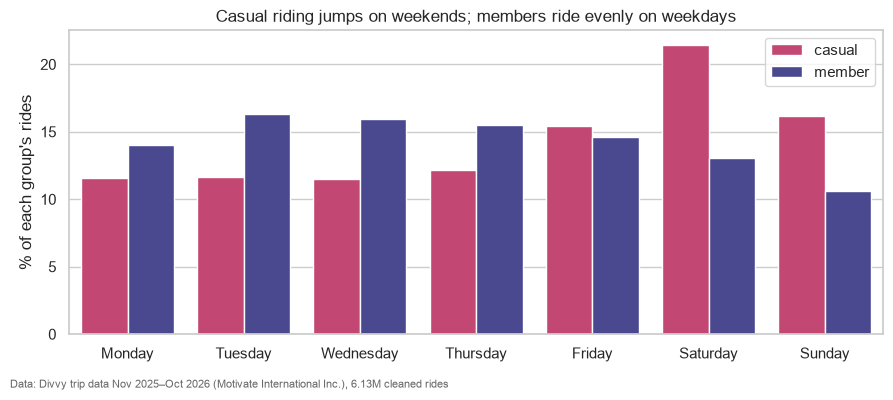

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=by_day, x="day_of_week", y="share", hue="member_casual", palette=COLORS, ax=ax)
ax.set(title="Casual riding jumps on weekends; members ride evenly on weekdays", xlabel="", ylabel="% of each group's rides")
ax.legend(title="")
finish(fig, "02_rides_by_day.png")

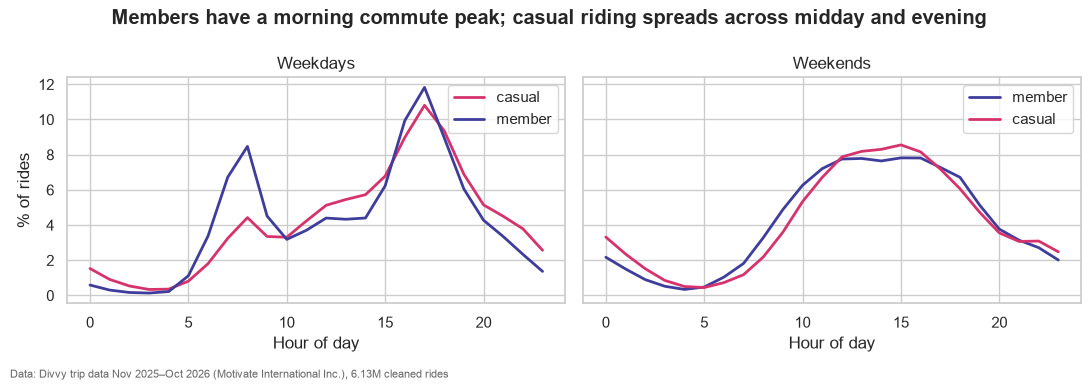

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, wk, label in [(axes[0], False, "Weekdays"), (axes[1], True, "Weekends")]:
    sns.lineplot(data=by_hour[by_hour.weekend == wk], x="hour", y="share", hue="member_casual", palette=COLORS, ax=ax, linewidth=2)
    ax.set(title=label, xlabel="Hour of day", ylabel="% of rides"); ax.legend(title="")
fig.suptitle("Members have a morning commute peak; casual riding spreads across midday and evening", fontweight="bold")
finish(fig, "03_rides_by_hour.png")

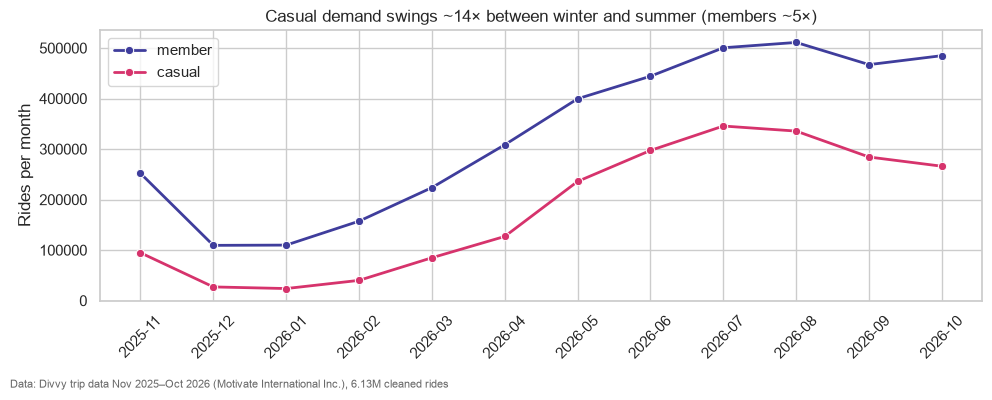

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(data=by_month, x="month", y="rides", hue="member_casual", palette=COLORS, marker="o", ax=ax, linewidth=2)
ax.set(title="Casual demand swings ~14× between winter and summer (members ~5×)", xlabel="", ylabel="Rides per month")
ax.tick_params(axis="x", rotation=45); ax.legend(title="")
finish(fig, "04_rides_by_month.png")

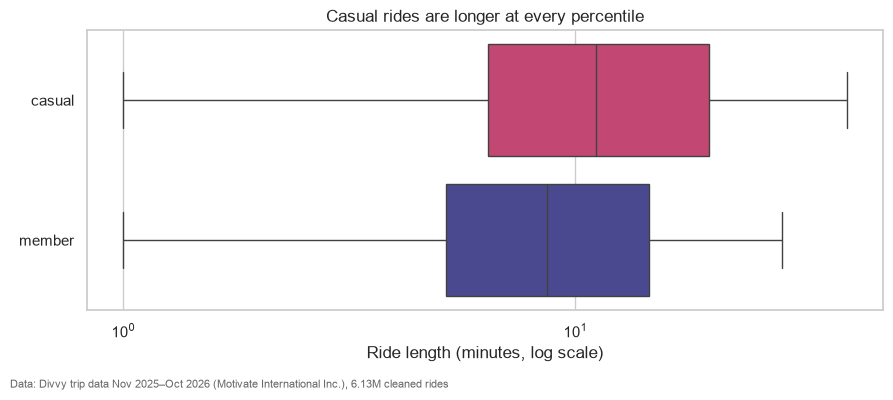

In [13]:
sample = q("SELECT member_casual, ride_length_min FROM trips USING SAMPLE 200000 ROWS")
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=sample, x="ride_length_min", y="member_casual", hue="member_casual", palette=COLORS, showfliers=False, ax=ax, legend=False)
ax.set(xscale="log", title="Casual rides are longer at every percentile", xlabel="Ride length (minutes, log scale)", ylabel="")
finish(fig, "05_ride_length.png")

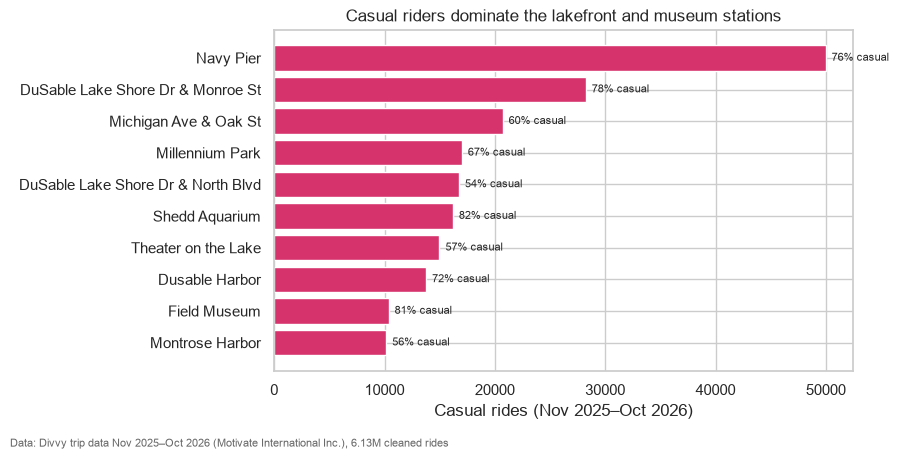

In [14]:
top = stations.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(top.start_station_name, top.casual_rides, color=COLORS["casual"])
for y, (n, s) in enumerate(zip(top.casual_rides, top.casual_share)):
    ax.text(n, y, f"  {s:.0f}% casual", va="center", fontsize=8)
ax.set(title="Casual riders dominate the lakefront and museum stations", xlabel="Casual rides (Nov 2025–Oct 2026)", ylabel="")
finish(fig, "06_top_casual_stations.png")

In [15]:
for name, df in {"overview": overview, "by_day": by_day, "by_hour": by_hour, "by_month": by_month,
                 "by_type": by_type, "top_stations": stations}.items():
    df.to_csv(CLEAN / f"tableau_{name}.csv", index=False)
sorted(p.name for p in CLEAN.glob("tableau_*.csv"))

['tableau_by_day.csv',
 'tableau_by_hour.csv',
 'tableau_by_month.csv',
 'tableau_by_type.csv',
 'tableau_overview.csv',
 'tableau_top_stations.csv']

## 6. Act
**Top three recommendations**
1. **Summer weekend membership offer** (findings 1, 3, 5): launch a seasonal or "weekend member" plan, promoted May–September and upgradable to a full annual membership, aimed at riders whose use is concentrated on summer weekends.
2. **Lakefront digital campaign** (finding 6): geo-targeted ads, in-app messages and QR codes at the docks of Navy Pier, Shedd Aquarium, Field Museum, Millennium Park and DuSable Lake Shore Dr, on weekends 12:00–18:00 in peak season, showing how much a member would have saved on a longer ride.
3. **Convert commuter-like casual riders** (findings 2, 4, 7): target casual riders who ride on weekdays at commute hours with a "you already ride like a member" message and a savings calculator; they are the easiest segment to convert.

**Limitations and next steps**
- No rider IDs: results describe rides, not people; cannot measure how many individuals would convert. Next step: join with account data (anonymised) to count riders and repeat behaviour.
- No prices or revenue: savings messages need current pricing from the finance team.
- ~20% of rides have no start station name (mostly e-bikes parked off-dock); station results use rides with known stations only.